# 🎥 ENet Semantic Segmentation — Video Inference

Notebook ini menjalankan **best model ENet** pada input video `.mp4` dan menghasilkan:
- Video output dengan **overlay segmentation mask** berwarna
- Video output dengan **side-by-side** (original | mask | overlay)
- Frame-by-frame mIoU jika ground truth tersedia

---
**Alur:**
1. Konfigurasi & Path
2. Arsitektur ENet (harus sama persis dengan saat training)
3. Load Model
4. Utilitas Visualisasi
5. Inferensi Video
6. Preview & Export

In [1]:
import os
import cv2
import json
import numpy as np
from pathlib import Path
from PIL import Image
from IPython.display import Video, display

import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import transforms

print(f"PyTorch  : {torch.__version__}")
print(f"OpenCV   : {cv2.__version__}")
print(f"CUDA     : {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU      : {torch.cuda.get_device_name(0)}")

# ==========================================
# 1. KONFIGURASI & PATH
# ==========================================

# ⚠️  SESUAIKAN: Path ke best_model.pth hasil training
MODEL_PATH  = "/kaggle/input/notebooks/ryosukeeh/enet-drva/ENet_Model_DRVA_vLapan/best_model.pth"   # <-- GANTI INI

# ⚠️  SESUAIKAN: Path ke config.json (disimpan otomatis saat training)
# Jika tidak ada, isi manual NUM_CLASSES, CLASS_NAMES, IMG_HEIGHT, IMG_WIDTH di bawah
CONFIG_PATH = "/kaggle/input/notebooks/ryosukeeh/enet-drva/ENet_Model_DRVA_vLapan/config.json"      # <-- GANTI INI (atau None)

# ⚠️  SESUAIKAN: Path ke video input .mp4
VIDEO_INPUT = "/kaggle/input/datasets/ryosukeeh/speedbump-7/speedbump7.mp4"        # <-- GANTI INI

# ---- Fallback manual jika tidak pakai config.json ----
# NUM_CLASSES  = 3
# CLASS_NAMES = ["background", "drivable_area", "semantic-area-UNNES"]
# IMG_HEIGHT   = 256
# IMG_WIDTH    = 512

# ---- Output ----
OUTPUT_DIR   = "/kaggle/working/video_output_drva"
os.makedirs(OUTPUT_DIR, exist_ok=True)

OUTPUT_OVERLAY   = os.path.join(OUTPUT_DIR, "output_overlay_drva.mp4")
OUTPUT_SIDEBYSIDE = os.path.join(OUTPUT_DIR, "output_sidebyside_drva.mp4")

# ---- Load config.json jika tersedia ----
if CONFIG_PATH and os.path.isfile(CONFIG_PATH):
    with open(CONFIG_PATH) as f:
        cfg = json.load(f)
    NUM_CLASSES = cfg["num_classes"]
    CLASS_NAMES = cfg["class_names"]
    IMG_HEIGHT  = cfg["img_height"]
    IMG_WIDTH   = cfg["img_width"]
    print(f"\n✅ Config loaded dari {CONFIG_PATH}")
else:
    print("\n⚠️  config.json tidak ditemukan, menggunakan nilai manual di atas.")

print(f"   NUM_CLASSES : {NUM_CLASSES}")
print(f"   CLASS_NAMES : {CLASS_NAMES}")
print(f"   Input size  : {IMG_HEIGHT}x{IMG_WIDTH}")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"   Device      : {device}")

PyTorch  : 2.10.0+cu128
OpenCV   : 4.13.0
CUDA     : True
GPU      : Tesla T4

✅ Config loaded dari /kaggle/input/notebooks/ryosukeeh/enet-drva/ENet_Model_DRVA_vLapan/config.json
   NUM_CLASSES : 4
   CLASS_NAMES : ['background', 'drivable_area', 'pothole', 'speed_bump']
   Input size  : 256x512
   Device      : cuda


In [2]:
# ==========================================
# 2. ARSITEKTUR ENET
# ==========================================
# ⚠️  Harus IDENTIK dengan arsitektur saat training!

def initialize_weights(*models):
    for model in models:
        for module in model.modules():
            if isinstance(module, (nn.Conv2d, nn.ConvTranspose2d)):
                nn.init.kaiming_normal_(module.weight)
                if module.bias is not None:
                    module.bias.data.zero_()
            elif isinstance(module, nn.BatchNorm2d):
                module.weight.data.fill_(1)
                module.bias.data.zero_()


class InitialBlock(nn.Module):
    def __init__(self, in_channels, use_prelu=True):
        super().__init__()
        self.pool  = nn.MaxPool2d(kernel_size=2, stride=2, ceil_mode=True)
        self.conv  = nn.Conv2d(in_channels, 16 - in_channels, 3, padding=1, stride=2)
        self.bn    = nn.BatchNorm2d(16)
        self.prelu = nn.PReLU(16) if use_prelu else nn.ReLU(inplace=True)

    def forward(self, x):
        x = torch.cat((self.pool(x), self.conv(x)), dim=1)
        return self.prelu(self.bn(x))


class BottleNeck(nn.Module):
    def __init__(self, in_channels, out_channels=None, dilation=1, downsample=False,
                 proj_ratio=4, upsample=False, asymetric=False,
                 regularize=True, p_drop=None, use_prelu=True):
        super().__init__()
        self.pad = 0
        self.upsample   = upsample
        self.downsample = downsample

        if out_channels is None:
            out_channels = in_channels
        else:
            self.pad = out_channels - in_channels

        if regularize: assert p_drop is not None
        if downsample: assert not upsample
        elif upsample: assert not downsample

        inter_channels = in_channels // proj_ratio

        if upsample:
            self.spatil_conv = nn.Conv2d(in_channels, out_channels, 1, bias=False)
            self.bn_up       = nn.BatchNorm2d(out_channels)
            self.unpool      = nn.MaxUnpool2d(kernel_size=2, stride=2)
        elif downsample:
            self.pool = nn.MaxPool2d(kernel_size=2, stride=2, return_indices=True)

        self.conv1  = nn.Conv2d(in_channels, inter_channels, 2 if downsample else 1,
                                stride=2 if downsample else 1, bias=False)
        self.bn1    = nn.BatchNorm2d(inter_channels)
        self.prelu1 = nn.PReLU() if use_prelu else nn.ReLU(inplace=True)

        if asymetric:
            self.conv2 = nn.Sequential(
                nn.Conv2d(inter_channels, inter_channels, kernel_size=(1, 5), padding=(0, 2)),
                nn.BatchNorm2d(inter_channels),
                nn.PReLU() if use_prelu else nn.ReLU(inplace=True),
                nn.Conv2d(inter_channels, inter_channels, kernel_size=(5, 1), padding=(2, 0)),
            )
        elif upsample:
            self.conv2 = nn.ConvTranspose2d(inter_channels, inter_channels,
                                            kernel_size=3, padding=1,
                                            output_padding=1, stride=2, bias=False)
        else:
            self.conv2 = nn.Conv2d(inter_channels, inter_channels, 3,
                                   padding=dilation, dilation=dilation, bias=False)

        self.bn2    = nn.BatchNorm2d(inter_channels)
        self.prelu2 = nn.PReLU() if use_prelu else nn.ReLU(inplace=True)
        self.conv3  = nn.Conv2d(inter_channels, out_channels, 1, bias=False)
        self.bn3    = nn.BatchNorm2d(out_channels)
        self.prelu3 = nn.PReLU() if use_prelu else nn.ReLU(inplace=True)
        self.regularizer = nn.Dropout2d(p_drop) if regularize else None
        self.prelu_out   = nn.PReLU() if use_prelu else nn.ReLU(inplace=True)

    def forward(self, x, indices=None, output_size=None):
        identity = x
        if self.upsample:
            assert (indices is not None) and (output_size is not None)
            identity = self.bn_up(self.spatil_conv(identity))
            if identity.size() != indices.size():
                pad = (indices.size(3) - identity.size(3), 0,
                       indices.size(2) - identity.size(2), 0)
                identity = F.pad(identity, pad, "constant", 0)
            identity = self.unpool(identity, indices=indices)
        elif self.downsample:
            identity, idx = self.pool(identity)
            if self.pad > 0:
                extras   = torch.zeros((identity.size(0), self.pad,
                                        identity.size(2), identity.size(3)), device=x.device)
                identity = torch.cat((identity, extras), dim=1)

        x = self.prelu1(self.bn1(self.conv1(x)))
        x = self.conv2(x)
        x = self.prelu2(self.bn2(x))
        x = self.prelu3(self.bn3(self.conv3(x)))
        if self.regularizer is not None:
            x = self.regularizer(x)
        if identity.size() != x.size():
            pad = (identity.size(3) - x.size(3), 0,
                   identity.size(2) - x.size(2), 0)
            x = F.pad(x, pad, "constant", 0)
        x = self.prelu_out(x + identity)
        if self.downsample:
            return x, idx
        return x


class ENet(nn.Module):
    def __init__(self, num_classes, in_channels=3):
        super().__init__()
        self.initial      = InitialBlock(in_channels)
        self.bottleneck10 = BottleNeck(16,  64,  downsample=True, p_drop=0.01)
        self.bottleneck11 = BottleNeck(64,        p_drop=0.01)
        self.bottleneck12 = BottleNeck(64,        p_drop=0.01)
        self.bottleneck13 = BottleNeck(64,        p_drop=0.01)
        self.bottleneck14 = BottleNeck(64,        p_drop=0.01)
        self.bottleneck20 = BottleNeck(64,  128, downsample=True, p_drop=0.1)
        self.bottleneck21 = BottleNeck(128,      p_drop=0.1)
        self.bottleneck22 = BottleNeck(128,      dilation=2,      p_drop=0.1)
        self.bottleneck23 = BottleNeck(128,      asymetric=True,  p_drop=0.1)
        self.bottleneck24 = BottleNeck(128,      dilation=4,      p_drop=0.1)
        self.bottleneck25 = BottleNeck(128,      p_drop=0.1)
        self.bottleneck26 = BottleNeck(128,      dilation=8,      p_drop=0.1)
        self.bottleneck27 = BottleNeck(128,      asymetric=True,  p_drop=0.1)
        self.bottleneck28 = BottleNeck(128,      dilation=16,     p_drop=0.1)
        self.bottleneck31 = BottleNeck(128,      p_drop=0.1)
        self.bottleneck32 = BottleNeck(128,      dilation=2,      p_drop=0.1)
        self.bottleneck33 = BottleNeck(128,      asymetric=True,  p_drop=0.1)
        self.bottleneck34 = BottleNeck(128,      dilation=4,      p_drop=0.1)
        self.bottleneck35 = BottleNeck(128,      p_drop=0.1)
        self.bottleneck36 = BottleNeck(128,      dilation=8,      p_drop=0.1)
        self.bottleneck37 = BottleNeck(128,      asymetric=True,  p_drop=0.1)
        self.bottleneck38 = BottleNeck(128,      dilation=16,     p_drop=0.1)
        self.bottleneck40 = BottleNeck(128, 64,  upsample=True,   p_drop=0.1, use_prelu=False)
        self.bottleneck41 = BottleNeck(64,       p_drop=0.1,      use_prelu=False)
        self.bottleneck42 = BottleNeck(64,       p_drop=0.1,      use_prelu=False)
        self.bottleneck50 = BottleNeck(64,  16,  upsample=True,   p_drop=0.1, use_prelu=False)
        self.bottleneck51 = BottleNeck(16,       p_drop=0.1,      use_prelu=False)
        self.fullconv     = nn.ConvTranspose2d(16, num_classes, kernel_size=3, padding=1,
                                              output_padding=1, stride=2, bias=False)
        initialize_weights(self)

    def forward(self, x):
        x = self.initial(x)
        sz1 = x.size()
        x, indices1 = self.bottleneck10(x)
        x = self.bottleneck11(x); x = self.bottleneck12(x)
        x = self.bottleneck13(x); x = self.bottleneck14(x)
        sz2 = x.size()
        x, indices2 = self.bottleneck20(x)
        x = self.bottleneck21(x); x = self.bottleneck22(x)
        x = self.bottleneck23(x); x = self.bottleneck24(x)
        x = self.bottleneck25(x); x = self.bottleneck26(x)
        x = self.bottleneck27(x); x = self.bottleneck28(x)
        x = self.bottleneck31(x); x = self.bottleneck32(x)
        x = self.bottleneck33(x); x = self.bottleneck34(x)
        x = self.bottleneck35(x); x = self.bottleneck36(x)
        x = self.bottleneck37(x); x = self.bottleneck38(x)
        x = self.bottleneck40(x, indices=indices2, output_size=sz2)
        x = self.bottleneck41(x); x = self.bottleneck42(x)
        x = self.bottleneck50(x, indices=indices1, output_size=sz1)
        x = self.bottleneck51(x)
        return self.fullconv(x)

print("✅ Arsitektur ENet siap.")

✅ Arsitektur ENet siap.


In [3]:
ckpt = torch.load(MODEL_PATH, map_location=device, weights_only=False)
print(type(ckpt))
print(ckpt.keys() if isinstance(ckpt, dict) else "Bukan dict — langsung state_dict")

<class 'collections.OrderedDict'>
odict_keys(['initial.conv.weight', 'initial.conv.bias', 'initial.bn.weight', 'initial.bn.bias', 'initial.bn.running_mean', 'initial.bn.running_var', 'initial.bn.num_batches_tracked', 'initial.prelu.weight', 'bottleneck10.conv1.weight', 'bottleneck10.bn1.weight', 'bottleneck10.bn1.bias', 'bottleneck10.bn1.running_mean', 'bottleneck10.bn1.running_var', 'bottleneck10.bn1.num_batches_tracked', 'bottleneck10.prelu1.weight', 'bottleneck10.conv2.weight', 'bottleneck10.bn2.weight', 'bottleneck10.bn2.bias', 'bottleneck10.bn2.running_mean', 'bottleneck10.bn2.running_var', 'bottleneck10.bn2.num_batches_tracked', 'bottleneck10.prelu2.weight', 'bottleneck10.conv3.weight', 'bottleneck10.bn3.weight', 'bottleneck10.bn3.bias', 'bottleneck10.bn3.running_mean', 'bottleneck10.bn3.running_var', 'bottleneck10.bn3.num_batches_tracked', 'bottleneck10.prelu3.weight', 'bottleneck10.prelu_out.weight', 'bottleneck11.conv1.weight', 'bottleneck11.bn1.weight', 'bottleneck11.bn1.bias

In [4]:
model = ENet(num_classes=NUM_CLASSES).to(device)

ckpt = torch.load(MODEL_PATH, map_location=device, weights_only=False)

if isinstance(ckpt, dict):
    # Coba semua kemungkinan key yang umum
    if "model_state_dict" in ckpt:
        model.load_state_dict(ckpt["model_state_dict"])
    elif "state_dict" in ckpt:
        model.load_state_dict(ckpt["state_dict"])
    else:
        # Isi dict langsung adalah state_dict
        model.load_state_dict(ckpt)
else:
    # File adalah state_dict langsung (hasil torch.save(model.state_dict(), ...))
    model.load_state_dict(ckpt)

model.eval()
print("✅ Model berhasil dimuat.")

✅ Model berhasil dimuat.


In [5]:
# ==========================================
# 4. UTILITAS VISUALISASI
# ==========================================

# ⚠️  Palet warna per kelas — tambah baris jika NUM_CLASSES > 8
# Format BGR (karena OpenCV pakai BGR)
COLOR_PALETTE_BGR = [
    (128, 64,  128),   # 0:  road
    (232, 35,  244),   # 1:  sidewalk
    (70,  70,  70),    # 2:  building
    (156, 102, 102),   # 3:  wall
    (153, 153, 190),   # 4:  fence
    (153, 153, 153),   # 5:  pole
    (30,  170, 250),   # 6:  traffic light
    (0,   220, 220),   # 7:  traffic sign
    (35,  142, 107),   # 8:  vegetation
    (152, 251, 152),   # 9:  terrain
    (180, 130, 70),    # 10: sky
    (60,  20,  220),   # 11: person
    (0,   0,   255),   # 12: rider
    (142, 0,   0),     # 13: car
    (70,  0,   0),     # 14: truck
    (100, 60,  0),     # 15: bus
    (100, 80,  0),     # 16: train
    (230, 0,   0),     # 17: motorcycle
    (32,  11,  119),   # 18: bicycle
]

MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
STD  = np.array([0.229, 0.224, 0.225], dtype=np.float32)

def preprocess_frame(frame_bgr):
    frame_rgb    = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)
    frame_resized = cv2.resize(frame_rgb, (IMG_WIDTH, IMG_HEIGHT),
                               interpolation=cv2.INTER_LINEAR)
    inp = frame_resized.astype(np.float32) / 255.0
    # inp = (inp - MEAN) / STD   # aktifkan jika training pakai normalisasi
    inp = torch.from_numpy(inp).permute(2, 0, 1).unsqueeze(0)
    return inp

def mask_to_color(mask_np):
    colored = np.zeros((*mask_np.shape, 3), dtype=np.uint8)
    for cls_idx, color in enumerate(COLOR_PALETTE_BGR[:NUM_CLASSES]):
        colored[mask_np == cls_idx] = color
    return colored

def draw_legend(frame):
    x, y0, dy = 10, 25, 22
    for i in range(NUM_CLASSES):
        y     = y0 + i * dy
        color = COLOR_PALETTE_BGR[i]
        name  = CLASS_NAMES[i] if i < len(CLASS_NAMES) else str(i)
        cv2.rectangle(frame, (x, y-12), (x+16, y+2), color, -1)
        cv2.rectangle(frame, (x, y-12), (x+16, y+2), (200,200,200), 1)
        cv2.putText(frame, name, (x+22, y),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.45, (255,255,255), 1, cv2.LINE_AA)
    return frame

def draw_nav_hud(frame, fps):
    """HUD navigasi di pojok kiri bawah."""
    h = frame.shape[0]
    direction    = "STRAIGHT"
    # if abs(error) > 5:
    #     direction = "RIGHT" if error > 0 else "LEFT"
    # status_color = (0, 255, 0) if status == "OK" else (0, 80, 255)
    lines = [
        (f"FPS      : {fps:.1f}",          (0,   255, 255)),
        (f"Infer    : {infer_ms:.1f} ms",  (200, 200, 200)),
        # (f"Error    : {error:+.1f} px",    (255, 255, 100)),
        # (f"Steering : {steering:+.4f}",    (255, 255, 100)),
        # (f"Dir      : {direction}",        (100, 255, 100)),
        # (f"Status   : {status}",           status_color),
    ]
    lh = 22
    x0 = 10
    y0 = h - len(lines) * lh - 10
    for i, (txt, col) in enumerate(lines):
        cv2.putText(frame, txt, (x0, y0 + i * lh),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.52, col, 1, cv2.LINE_AA)


def draw_fps(frame, fps):
    label = f"FPS: {fps:.1f}"
    cv2.putText(frame, label, (frame.shape[1] - 120, 25),
                cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 255), 2, cv2.LINE_AA)
    return frame


print("✅ Fungsi utilitas siap.")

✅ Fungsi utilitas siap.


In [6]:
# ==========================================
# 5. INFERENSI VIDEO
# ==========================================
# Menghasilkan DUA video output:
#   A) output_overlay.mp4    — frame asli + mask transparan di atasnya
#   B) output_sidebyside.mp4 — tiga panel: Original | Mask | Overlay

# ⚠️  Sesuaikan jika perlu
OVERLAY_ALPHA  = 0.45   # transparansi mask (0.0 – 1.0)
SKIP_FRAMES    = 1      # proses setiap N frame (1 = semua frame, 2 = skip 1, dst)
                        # naikkan ke 2-3 untuk mempercepat jika video panjang

import time

cap = cv2.VideoCapture(VIDEO_INPUT)
assert cap.isOpened(), f"❌ Tidak bisa membuka video: {VIDEO_INPUT}"

ORIG_W   = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
ORIG_H   = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
FPS_IN   = cap.get(cv2.CAP_PROP_FPS)
TOTAL_F  = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
FPS_OUT  = FPS_IN / SKIP_FRAMES

print(f"Video input  : {VIDEO_INPUT}")
print(f"Resolusi     : {ORIG_W}x{ORIG_H} | FPS: {FPS_IN:.2f} | Total frame: {TOTAL_F}")
print(f"Inferensi    : setiap {SKIP_FRAMES} frame → output FPS: {FPS_OUT:.2f}")
print(f"Input model  : {IMG_WIDTH}x{IMG_HEIGHT}")
print()

# Side-by-side: tiga panel masing-masing ORIG_W x ORIG_H
SBS_W = ORIG_W * 3
SBS_H = ORIG_H

fourcc_mp4 = cv2.VideoWriter_fourcc(*'mp4v')
writer_overlay = cv2.VideoWriter(OUTPUT_OVERLAY,   fourcc_mp4, FPS_OUT, (ORIG_W, ORIG_H))
writer_sbs     = cv2.VideoWriter(OUTPUT_SIDEBYSIDE, fourcc_mp4, FPS_OUT, (SBS_W,  SBS_H))

frame_count   = 0
written_count = 0
fps_times     = []

print("Memulai inferensi...")

with torch.no_grad():
    while True:
        ret, frame_bgr = cap.read()
        if not ret:
            break

        frame_count += 1
        if frame_count % SKIP_FRAMES != 0:
            continue

        t0 = time.time()

        # ── Preprocessing & Inferensi ─────────────────────────────────────
        inp     = preprocess_frame(frame_bgr).to(device, non_blocking=True)
        logits  = model(inp)
        pred_np = logits.argmax(dim=1).squeeze(0).cpu().numpy().astype(np.uint8)

        infer_ms = (time.time() - t0) * 1000

        # ── Warnai mask & resize ke ukuran original ───────────────────────
        mask_colored = mask_to_color(pred_np)
        mask_colored = cv2.resize(mask_colored, (ORIG_W, ORIG_H),
                                  interpolation=cv2.INTER_NEAREST)

        # ── Overlay standar ───────────────────────────────────────────────
        overlay = cv2.addWeighted(frame_bgr, 1 - OVERLAY_ALPHA,
                                  mask_colored, OVERLAY_ALPHA, 0)

        # --- Hitung FPS ---
        t1 = time.time()
        fps_times.append(time.time() - t0)
        fps = 1.0 / np.mean(fps_times[-30:])

        display_frame = overlay.copy()
        # draw_path_on_frame(display_frame, active_wps, target, robot_pos, lb, rb)
        draw_nav_hud(display_frame, fps)
        draw_legend(display_frame)

        # out.write(display_frame)

        # --- Buat side-by-side ---
        # Panel kiri  : frame asli
        # Panel tengah: mask berwarna
        # Panel kanan : overlay
        panel_orig = frame_bgr.copy()
        panel_mask = mask_colored.copy()
        panel_over = overlay.copy()

        # Label tiap panel
        for panel, label in [(panel_orig, "Original"),
                             (panel_mask, "Segmentation Mask"),
                             (panel_over, "Overlay")]:
            cv2.putText(panel, label, (10, 30),
                        cv2.FONT_HERSHEY_SIMPLEX, 1.0, (255, 255, 255), 2, cv2.LINE_AA)
            cv2.putText(panel, label, (10, 30),
                        cv2.FONT_HERSHEY_SIMPLEX, 1.0, (0, 0, 0), 1, cv2.LINE_AA)

        sbs_frame = np.concatenate([panel_orig, panel_mask, panel_over], axis=1)
        # draw_legend(sbs_frame, CLASS_NAMES, COLOR_PALETTE_BGR)
        writer_sbs.write(sbs_frame)

        frame_count += 1
        if frame_count % 30 == 0:
            print(f"Frame {frame_count} | FPS: {fps:.1f} | Infer: {infer_ms:.1f} ms")

cap.release()
writer_overlay.release()
writer_sbs.release()

print(f"\n✅ Selesai! {written_count} frame diproses.")
print(f"   Output overlay    : {OUTPUT_OVERLAY}")
print(f"   Output side-by-side : {OUTPUT_SIDEBYSIDE}")

Video input  : /kaggle/input/datasets/ryosukeeh/speedbump-7/speedbump7.mp4
Resolusi     : 1920x1080 | FPS: 30.00 | Total frame: 403
Inferensi    : setiap 1 frame → output FPS: 30.00
Input model  : 512x256

Memulai inferensi...
Frame 30 | FPS: 8.4 | Infer: 20.1 ms
Frame 60 | FPS: 13.9 | Infer: 16.1 ms
Frame 90 | FPS: 40.9 | Infer: 14.9 ms
Frame 120 | FPS: 41.3 | Infer: 16.2 ms
Frame 150 | FPS: 39.8 | Infer: 15.7 ms
Frame 180 | FPS: 40.2 | Infer: 18.3 ms
Frame 210 | FPS: 41.2 | Infer: 15.2 ms
Frame 240 | FPS: 41.6 | Infer: 15.7 ms
Frame 270 | FPS: 41.3 | Infer: 17.9 ms
Frame 300 | FPS: 41.0 | Infer: 16.4 ms
Frame 330 | FPS: 41.0 | Infer: 16.9 ms
Frame 360 | FPS: 40.9 | Infer: 19.4 ms
Frame 390 | FPS: 41.9 | Infer: 16.0 ms
Frame 420 | FPS: 42.1 | Infer: 16.0 ms
Frame 450 | FPS: 40.5 | Infer: 18.1 ms
Frame 480 | FPS: 40.2 | Infer: 15.5 ms
Frame 510 | FPS: 40.1 | Infer: 24.6 ms
Frame 540 | FPS: 40.6 | Infer: 15.8 ms
Frame 570 | FPS: 42.1 | Infer: 15.4 ms
Frame 600 | FPS: 41.9 | Infer: 15.1 

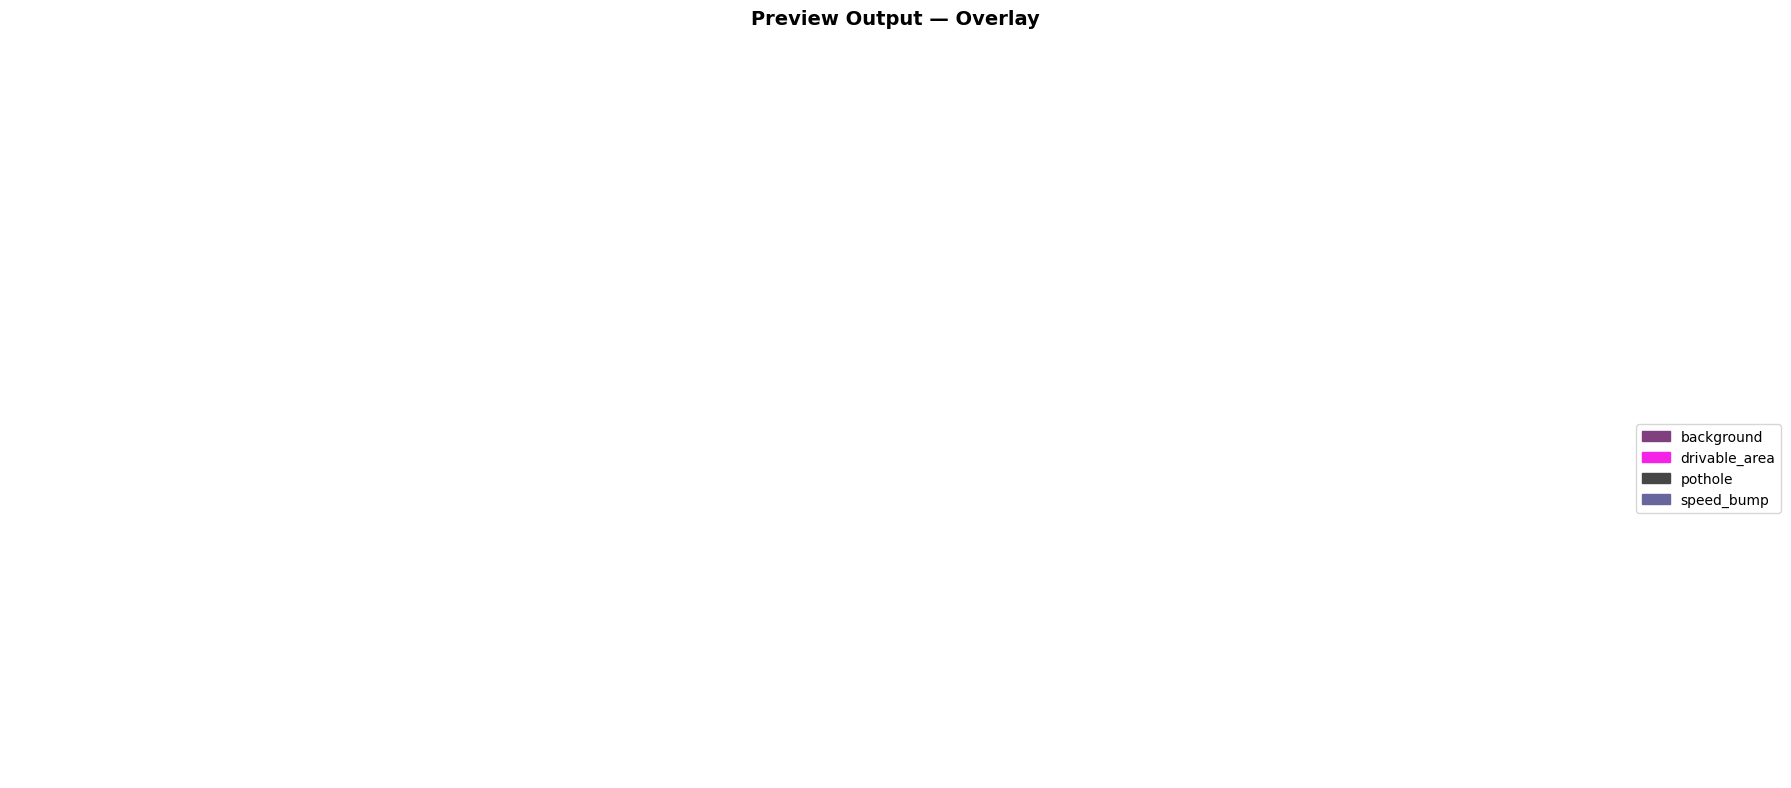

Preview overlay disimpan.


In [7]:
# ==========================================
# 6A. PREVIEW VIDEO — OVERLAY
# ==========================================
# Kaggle tidak bisa memutar video .mp4 langsung,
# jadi kita tampilkan beberapa frame sebagai preview.

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# Ambil N frame dari video output untuk preview
N_PREVIEW = 6
cap_prev  = cv2.VideoCapture(OUTPUT_OVERLAY)
total_out = int(cap_prev.get(cv2.CAP_PROP_FRAME_COUNT))
step      = max(1, total_out // N_PREVIEW)

fig, axes = plt.subplots(2, 3, figsize=(18, 8))
fig.suptitle("Preview Output — Overlay", fontsize=14, fontweight='bold')

for i, ax in enumerate(axes.flat):
    cap_prev.set(cv2.CAP_PROP_POS_FRAMES, i * step)
    ret, frame = cap_prev.read()
    if ret:
        ax.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
        ax.set_title(f"Frame {i * step}")
    ax.axis('off')

# Legend
palette_rgb = [(c[2]/255, c[1]/255, c[0]/255) for c in COLOR_PALETTE_BGR]
patches = [mpatches.Patch(color=palette_rgb[c], label=CLASS_NAMES[c])
           for c in range(min(NUM_CLASSES, len(COLOR_PALETTE_BGR)))]
plt.legend(handles=patches, bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "preview_overlay.png"), dpi=120, bbox_inches='tight')
plt.show()
cap_prev.release()
print("Preview overlay disimpan.")

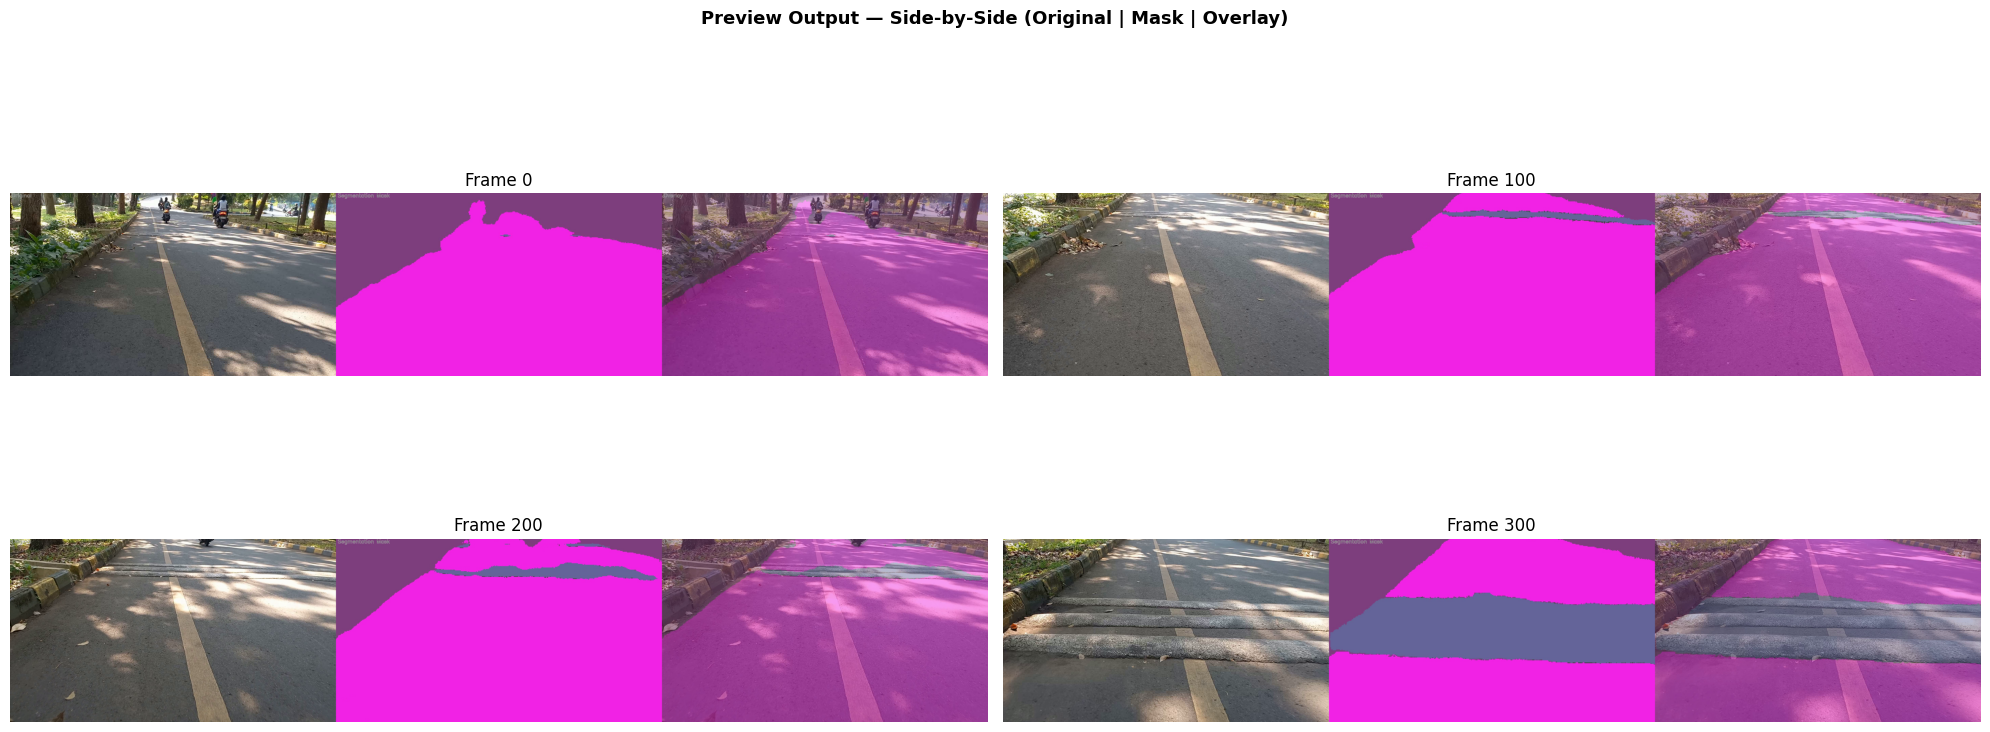

Preview side-by-side disimpan.


In [8]:
# ==========================================
# 6B. PREVIEW VIDEO — SIDE-BY-SIDE
# ==========================================

cap_sbs  = cv2.VideoCapture(OUTPUT_SIDEBYSIDE)
total_sbs = int(cap_sbs.get(cv2.CAP_PROP_FRAME_COUNT))
step_sbs  = max(1, total_sbs // 4)

fig, axes = plt.subplots(2, 2, figsize=(20, 9))
fig.suptitle("Preview Output — Side-by-Side (Original | Mask | Overlay)",
             fontsize=13, fontweight='bold')

for i, ax in enumerate(axes.flat):
    cap_sbs.set(cv2.CAP_PROP_POS_FRAMES, i * step_sbs)
    ret, frame = cap_sbs.read()
    if ret:
        ax.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
        ax.set_title(f"Frame {i * step_sbs}")
    ax.axis('off')

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "preview_sidebyside.png"), dpi=100, bbox_inches='tight')
plt.show()
cap_sbs.release()
print("Preview side-by-side disimpan.")

Menghitung statistik distribusi kelas...

--- Rata-rata Distribusi Kelas (80 frame sampel) ---
       background :  15.1%  ██████
    drivable_area :  74.7%  █████████████████████████████
          pothole :   0.1%  
       speed_bump :  10.2%  ████


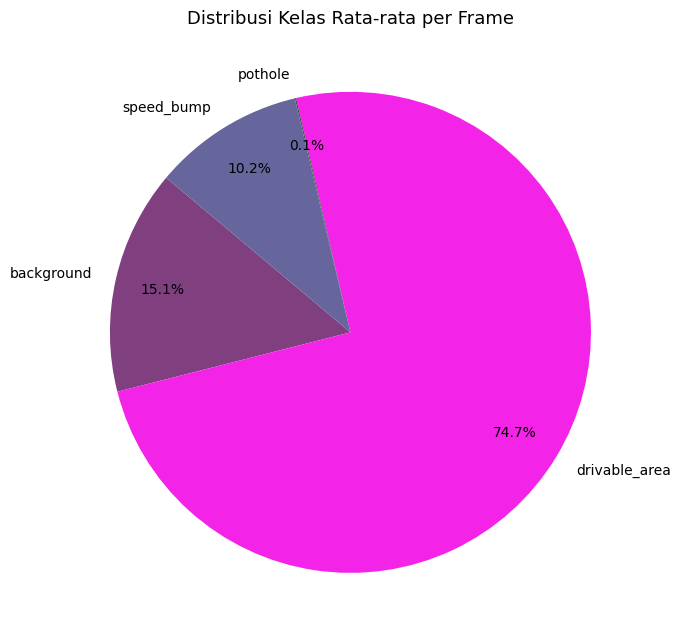

Pie chart distribusi disimpan.

📦 Semua output tersedia di Output panel Kaggle:
   🎬 /kaggle/working/video_output_drva/output_overlay_drva.mp4
   🎬 /kaggle/working/video_output_drva/output_sidebyside_drva.mp4
   🖼️  /kaggle/working/video_output_drva/preview_overlay.png
   🖼️  /kaggle/working/video_output_drva/preview_sidebyside.png
   📊 /kaggle/working/video_output_drva/class_distribution.png


In [9]:
# ==========================================
# 6C. STATISTIK SEGMENTASI PER FRAME
# ==========================================
# Hitung distribusi rata-rata kelas di seluruh video

print("Menghitung statistik distribusi kelas...")
cap_stat = cv2.VideoCapture(OUTPUT_OVERLAY)
total_stat = int(cap_stat.get(cv2.CAP_PROP_FRAME_COUNT))

# Re-run inferensi ringan hanya untuk statistik
# (tanpa menulis video, lebih cepat)
cap_raw  = cv2.VideoCapture(VIDEO_INPUT)
class_pixels_total = np.zeros(NUM_CLASSES, dtype=np.float64)
frame_cnt_stat = 0

SAMPLE_EVERY = max(1, SKIP_FRAMES * 5)  # lebih jarang untuk kecepatan

with torch.no_grad():
    fc = 0
    while True:
        ret, frame_bgr = cap_raw.read()
        if not ret: break
        fc += 1
        if fc % SAMPLE_EVERY != 0: continue

        inp     = preprocess_frame(frame_bgr).to(device, non_blocking=True)
        logits  = model(inp)
        pred_np = logits.argmax(dim=1).squeeze(0).cpu().numpy().astype(np.uint8)

        total_px = pred_np.size
        for c in range(NUM_CLASSES):
            class_pixels_total[c] += (pred_np == c).sum() / total_px
        frame_cnt_stat += 1

cap_raw.release()

if frame_cnt_stat > 0:
    avg_dist = class_pixels_total / frame_cnt_stat
    print(f"\n--- Rata-rata Distribusi Kelas ({frame_cnt_stat} frame sampel) ---")
    for c in range(NUM_CLASSES):
        bar = '█' * int(avg_dist[c] * 40)
        print(f"  {CLASS_NAMES[c]:>15s} : {avg_dist[c]*100:5.1f}%  {bar}")

    # Plot pie chart distribusi
    fig, ax = plt.subplots(figsize=(7, 7))
    palette_rgb = [(c[2]/255, c[1]/255, c[0]/255) for c in COLOR_PALETTE_BGR[:NUM_CLASSES]]
    wedges, texts, autotexts = ax.pie(
        avg_dist, labels=CLASS_NAMES[:NUM_CLASSES],
        colors=palette_rgb, autopct='%1.1f%%',
        startangle=140, pctdistance=0.8
    )
    ax.set_title("Distribusi Kelas Rata-rata per Frame", fontsize=13)
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, "class_distribution.png"), dpi=120)
    plt.show()
    print("Pie chart distribusi disimpan.")

print(f"\n{'='*50}")
print("📦 Semua output tersedia di Output panel Kaggle:")
print(f"   🎬 {OUTPUT_OVERLAY}")
print(f"   🎬 {OUTPUT_SIDEBYSIDE}")
print(f"   🖼️  {OUTPUT_DIR}/preview_overlay.png")
print(f"   🖼️  {OUTPUT_DIR}/preview_sidebyside.png")
print(f"   📊 {OUTPUT_DIR}/class_distribution.png")